# LEDGAR — a TF-IDF + logistic regression baseline (milestone m1)

> **Summary**
> - Unigrams and bigrams weighted by TF-IDF (173 477 features, fitted on the training clauses) feed a
>   multinomial logistic regression: 17 M parameters, about two minutes on a laptop CPU.
> - Searched on validation: the strength of the penalty matters most (macro-F1 0.697 at C = 0.3, 0.827 at
>   C = 30), bigrams add 3 to 4 points, class weights change nothing. Chosen: bigrams, C = 30, no class weight.
> - Validation macro-F1 **0.827** (accuracy 0.879): the bar every later model has to clear.
> - Its errors: the rare types (mean F1 0.67 under 300 training clauses) and near-synonym pairs (*Applicable
>   Laws* read as *Governing Laws* for 45 of its 69 validation clauses).

Every later model (BiLSTM, DistilBERT, LoRA) is measured against this baseline. Runs in about 20 minutes on a
laptop (13 fits of logistic regression).

In [1]:
import inspect
import warnings
from dataclasses import replace

warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars without ipywidgets

import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hub_logging

from ledgar import data, metrics, plots, runs, train_tfidf
from ledgar.config import Config, set_seed

hub_logging.set_verbosity_error()
pd.set_option("display.width", 140)

## Setup

`START` is the starting configuration: unigrams and bigrams, `C = 1`, no class weight. Searched: n-grams up to 1
or 2 words, `C` (inverse of the L2 penalty) in {0.3, 1, 3, 10, 30} (30 was added after a first run on unigrams
peaked at the edge, `C = 10`), then `class_weight="balanced"` (each type weighted by $N / (100 \times n_k)$, up to
26 for *Books*). `FAST_RUN=1` keeps two points.

In [2]:
cfg = Config.from_env()
set_seed(cfg.seed)
START = replace(cfg, tfidf_ngram_max=2, logreg_c=1.0, class_weight=None)
GRID = {"ngram_max": [1, 2], "c": [0.3, 1, 3, 10, 30], "class_weight": [None]}
if cfg.fast_run:
    GRID = {"ngram_max": [1, 2], "c": [1], "class_weight": [None]}
FIGURES = cfg.path(cfg.reports_dir, "figures")
print(
    cfg, "| start: n-grams <=", START.tfidf_ngram_max, "| C =", START.logreg_c, "| solver:", cfg.logreg_solver
)

fast_run=False | seed=0 | device=mps | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=3 | start: n-grams <= 2 | C = 1.0 | solver: lbfgs


The three official splits, at the dataset revision pinned in `Config`:

In [3]:
ledgar = data.load_ledgar(cfg)
LABELS = data.label_names(ledgar)
train_texts, train_labels = ledgar["train"]["text"], np.array(ledgar["train"]["label"])
val_texts, y_val = ledgar["validation"]["text"], np.array(ledgar["validation"]["label"])
train_counts = np.bincount(train_labels, minlength=cfg.n_classes)
print("train:", len(train_texts), "| validation:", len(val_texts))

train: 60000 | validation: 10000


## 1. What does a clause look like as a bag of n-grams?

A clause becomes a vector with one entry per word (or pair of words) of the vocabulary. With `sublinear_tf` the
weight of term $t$ in clause $d$ is $(1 + \log \mathrm{tf}_{t,d}) \times \mathrm{idf}_t$, where
$\mathrm{idf}_t = \ln\frac{1 + N}{1 + \mathrm{df}_t} + 1$ is high for words that few clauses use; each row is
then divided by its L2 norm. Word order is lost. The vectorizer is fitted on the training clauses only;
validation only uses it.

In [4]:
print(inspect.getsource(train_tfidf.make_vectorizer))
vectorizer = train_tfidf.make_vectorizer(START)
X_train = vectorizer.fit_transform(train_texts)
X_val = vectorizer.transform(val_texts)
print(f"X_train {X_train.shape}, {X_train.nnz / X_train.shape[0]:.0f} non-zero features per clause")
print("a few features:", list(vectorizer.get_feature_names_out()[::20000][:8]))

def make_vectorizer(cfg: Config, ngram_max: int | None = None) -> TfidfVectorizer:
    """Lower-cased words, n-grams up to `ngram_max`, seen in >= min_df training clauses, sublinear tf."""
    return TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, ngram_max or cfg.tfidf_ngram_max),
        min_df=cfg.tfidf_min_df,
        sublinear_tf=True,
        dtype=np.float32,
    )



X_train (60000, 173477), 148 non-zero features per clause
a few features: ['00', 'applications copyrights', 'conducted ii', 'exclusive control', 'indirect references', 'nonprevailing party', 'plans stock', 'service addresses']


In [5]:
row_norms = np.sqrt(X_train.multiply(X_train).sum(axis=1)).A1
docs_per_feature = (X_train > 0).sum(axis=0).A1
assert X_val.shape[1] == X_train.shape[1], "validation uses the training vocabulary"
assert docs_per_feature.min() >= cfg.tfidf_min_df, "every feature appears in >= min_df training clauses"
assert np.allclose(row_norms[row_norms > 0], 1, atol=1e-3), "each clause vector has unit L2 norm"
print("verified: TF-IDF fitted on train only, rows L2-normalised")

verified: TF-IDF fitted on train only, rows L2-normalised


→ **Consequence:** with unigrams and bigrams seen in at least two training clauses, the vocabulary has 173 477
features and a clause activates 148 of them: the matrix is 99.9 % zeros, which is why a linear model on it trains
in a couple of minutes on a CPU. Bigrams such as *governed by* or *written notice* carry much of the phrasing that
tells clause types apart; section 3 measures whether they are worth a vocabulary 14 times larger than unigrams
alone (12 135).

## 2. How far does one model at the starting configuration get?

Multinomial logistic regression is a softmax over the 100 types on top of the TF-IDF vector:
$\hat y = \mathrm{softmax}(W x + b)$ with $W \in \mathbb{R}^{100 \times V}$, trained with the cross-entropy plus
an L2 penalty of strength $1/C$. It has $100 \times (V + 1)$ parameters, all in one layer. One fit at the
starting configuration, next to the floor of `01_explore_ledgar`.

In [6]:
logreg, seconds, converged = train_tfidf.fit_timed(train_tfidf.make_logreg(START), X_train, train_labels)
pred_val = logreg.predict(X_val)
lazy = data.lazy_baseline(train_labels, len(y_val))
for name, pred in [("lazy floor", lazy), ("tf-idf + logreg", pred_val)]:
    acc, mf1 = metrics.accuracy(y_val, pred), metrics.macro_f1_score(y_val, pred, cfg.n_classes)
    print(f"{name:<18}accuracy {acc:.4f}   macro-F1 {mf1:.4f}")
print(f"fit: {seconds:.1f} s, converged: {converged}, parameters: {train_tfidf.count_parameters(logreg):,}")

lazy floor        accuracy 0.0494   macro-F1 0.0010
tf-idf + logreg   accuracy 0.8512   macro-F1 0.7741
fit: 98.6 s, converged: True, parameters: 17,347,800


In [7]:
assert train_tfidf.count_parameters(logreg) == cfg.n_classes * (X_train.shape[1] + 1), "100 x (V + 1)"
assert converged, "raise logreg_max_iter: the solver stopped before converging"
assert metrics.macro_f1_score(y_val, pred_val, cfg.n_classes) > 10 * metrics.macro_f1_score(y_val, lazy), (
    "far above the floor"
)
print("verified: parameters = 100 x (V + 1), converged, far above the lazy floor")

verified: parameters = 100 x (V + 1), converged, far above the lazy floor


→ **Consequence:** one logistic regression at the starting configuration reaches 0.774 validation macro-F1 (accuracy
0.851), against 0.001 for the floor, in under two minutes on a CPU. The 8-point gap between accuracy and
macro-F1 is the cost of the imbalance: the frequent boilerplate types are easy, the rare ones pull the mean down.
17.3 M parameters, all in one linear layer: a quarter of DistilBERT's 67 M.

## 3. Which settings matter? (validation)

Every configuration is fitted on train and scored on validation macro-F1, the only criterion; the test split is
not read. Two stages, one factor at a time for the expensive one:
1. n-grams × `C`, without class weights: 10 fits, one at a time (an lbfgs fit on bigrams holds about 3 GB,
   $100 \times V$ weights and the 10 past gradients of L-BFGS: two in parallel already swap on a 16 GB laptop);
2. `class_weight="balanced"` at the best (n-grams, `C`) of stage 1. Weights up to 26 make the problem badly
   conditioned and the fit slow, so it is run once, where it can matter, and kept only if validation macro-F1
   improves.

In [8]:
args = (train_texts, train_labels, val_texts, y_val, cfg)
stage1 = train_tfidf.grid_search(*args, GRID)
stage1.round(4)

,ngram_max,c,class_weight,vocabulary,val_accuracy,val_macro_f1,fit_s,converged
0,2,30.0,none,173477,0.8794,0.8265,137.9,True
1,2,10.0,none,173477,0.8780,0.8187,146.0,True
2,2,3.0,none,173477,0.8691,0.8036,158.9,True
3,1,30.0,none,12135,0.8578,0.7922,21.4,True
4,1,10.0,none,12135,0.8590,0.7917,17.9,True
5,1,3.0,none,12135,0.8557,0.7841,15.4,True
6,2,1.0,none,173477,0.8510,0.7734,128.9,True
7,1,1.0,none,12135,0.8435,0.7615,10.8,True
8,1,0.3,none,12135,0.8173,0.7096,7.1,True
9,2,0.3,none,173477,0.8142,0.6966,133.1,True


In [9]:
top = stage1.iloc[0]
weighted = {"ngram_max": [int(top["ngram_max"])], "c": [float(top["c"])], "class_weight": ["balanced"]}
stage2 = train_tfidf.grid_search(*args, weighted)
grid = pd.concat([stage1, stage2]).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
grid.round(4)

,ngram_max,c,class_weight,vocabulary,val_accuracy,val_macro_f1,fit_s,converged
0,2,30.0,none,173477,0.8794,0.8265,137.9,True
1,2,30.0,balanced,173477,0.8762,0.8262,133.7,True
2,2,10.0,none,173477,0.8780,0.8187,146.0,True
3,2,3.0,none,173477,0.8691,0.8036,158.9,True
4,1,30.0,none,12135,0.8578,0.7922,21.4,True
5,1,10.0,none,12135,0.8590,0.7917,17.9,True
6,1,3.0,none,12135,0.8557,0.7841,15.4,True
7,2,1.0,none,173477,0.8510,0.7734,128.9,True
8,1,1.0,none,12135,0.8435,0.7615,10.8,True
9,1,0.3,none,12135,0.8173,0.7096,7.1,True


In [10]:
best = grid.iloc[0]
CHOSEN = {
    "tfidf_ngram_max": int(best["ngram_max"]),
    "logreg_c": float(best["c"]),
    "class_weight": None if best["class_weight"] == "none" else best["class_weight"],
}
print("best on validation:", CHOSEN, f"-> macro-F1 {best['val_macro_f1']:.4f}")
assert stage1["converged"].all(), "every unweighted fit converged"
assert best["val_macro_f1"] >= grid.loc[(grid["ngram_max"] == 2) & (grid["c"] == 1), "val_macro_f1"].max()
print("verified: chosen on validation; tests/test_tfidf.py checks that Config holds this choice")

best on validation: {'tfidf_ngram_max': 2, 'logreg_c': 30.0, 'class_weight': None} -> macro-F1 0.8265
verified: chosen on validation; tests/test_tfidf.py checks that Config holds this choice


→ **Consequence:** the strength of the penalty matters most: with bigrams, validation macro-F1 climbs from 0.697 at
C = 0.3 to 0.827 at C = 30, because a weaker penalty lets the model rely on rare but telling n-grams. Bigrams add 3
to 4 points at every C ≥ 3. `class_weight="balanced"` changes nothing (0.8262 against 0.8265), so it is dropped:
the decision metric already gives the rare types their weight. The chosen configuration (bigrams, C = 30, no class
weight) is the default of `Config`, so `make m1` reproduces this model. One limit, stated rather than fixed: the
best C sits on the edge of the grid, and a larger C might add a little more. This was noticed after the final
cell had written the test predictions; choosing a configuration after the test is read would make the test score
optimistic, so the grid was not extended.

## 4. Where does the chosen model fail? (validation)

The chosen configuration, refitted as one pipeline (text in, label out): the types it gets wrong, the pairs it
confuses, and two slices: the frequency band of the type (tail under 300 training clauses, head 1 000 or more)
and clauses that also appear word for word in the training set.

In [11]:
cfg = replace(cfg, **CHOSEN)
model, seconds, _ = train_tfidf.fit_timed(train_tfidf.make_pipeline(cfg), train_texts, train_labels)
logits_val = model.decision_function(val_texts)
pred_val = logits_val.argmax(axis=1)
val_metrics = {
    "accuracy": metrics.accuracy(y_val, pred_val),
    "macro_f1": metrics.macro_f1_score(y_val, pred_val, cfg.n_classes),
}
report = metrics.per_class_report(y_val, pred_val, LABELS, train_counts=train_counts)
print(val_metrics, f"| fit {seconds:.1f} s")
report[report["support"] > 0].head(12).round(3)

{'accuracy': 0.8794, 'macro_f1': 0.8264685231705821} | fit 139.1 s


,label,train_count,support,predicted,precision,recall,f1
1,Applicable Laws,352,69,34,0.588,0.290,0.388
2,Qualifications,47,8,2,1.000,0.250,0.400
3,Venues,131,19,20,0.450,0.474,0.462
4,Jurisdictions,202,33,25,0.560,0.424,0.483
5,Assigns,31,3,1,1.000,0.333,0.500
6,Enforcements,201,46,26,0.769,0.435,0.556
7,Powers,125,15,10,0.700,0.467,0.560
8,Tax Withholdings,380,57,49,0.653,0.561,0.604
9,Approvals,178,26,19,0.737,0.538,0.622
10,Agreements,252,22,22,0.636,0.636,0.636


In [12]:
C = metrics.confusion(y_val, pred_val, cfg.n_classes)
pairs = metrics.most_confused(C, k=10, label_names=LABELS)
pairs

,class_a,class_b,label_a,label_b,a_as_b,b_as_a,total
0,4,47,Applicable Laws,Governing Laws,45,12,57
1,28,29,Defined Terms,Definitions,18,16,34
2,86,99,Tax Withholdings,Withholdings,17,13,30
3,9,10,Authority,Authorizations,10,14,24
4,41,42,Expenses,Fees,8,14,22
5,76,98,Representations,Warranties,8,14,22
6,49,50,Indemnifications,Indemnity,7,13,20
7,13,84,Binding Effects,Successors,6,12,18
8,63,97,No Waivers,Waivers,15,3,18
9,88,89,Terminations,Terms,7,11,18


In [13]:
bands = data.frequency_band(train_counts)
report["band"] = bands[[LABELS.index(name) for name in report["label"]]]
by_band = report[report["support"] > 0].groupby("band")[["f1", "precision", "recall"]].mean()
seen = data.seen_in_train(ledgar, "validation")
by_seen = metrics.f1_by_group(y_val, pred_val, np.where(seen, "seen in train", "not seen"), cfg.n_classes)
print(by_band.round(3), "\n")
print(by_seen.round(4))

           f1  precision  recall
band                            
head    0.924      0.909   0.941
middle  0.853      0.861   0.850
tail    0.673      0.788   0.614 

           group     n  accuracy  macro_f1
0       not seen  9730    0.8761    0.8223
1  seen in train   270    1.0000    1.0000


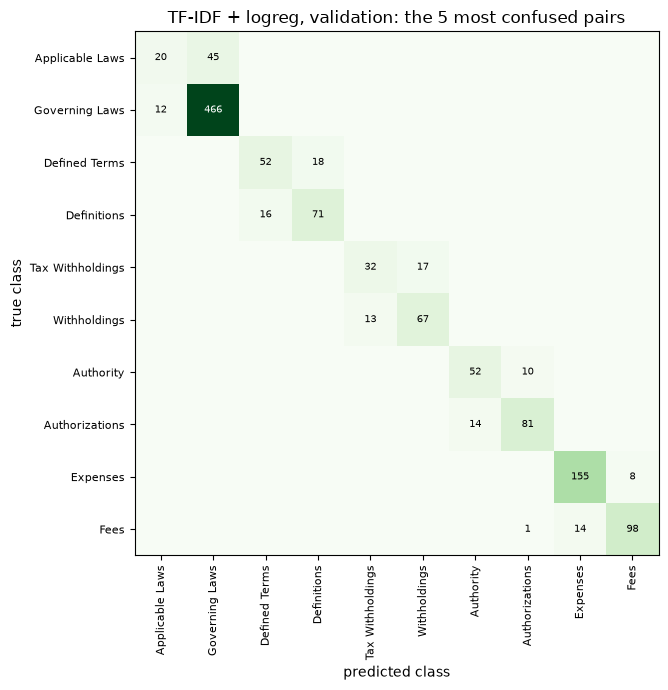

In [14]:
worst = list(dict.fromkeys(pairs[["class_a", "class_b"]].head(5).to_numpy().ravel()))
fig = plots.plot_confusion(
    C[np.ix_(worst, worst)],
    [LABELS[k] for k in worst],
    title="TF-IDF + logreg, validation: the 5 most confused pairs",
    path=FIGURES / "tfidf_confusion_pairs.png",
)

In [15]:
assert report["support"].sum() == len(y_val) and len(pairs) == 10
seen_accuracy = by_seen.set_index("group")["accuracy"]
if not cfg.fast_run:
    assert seen_accuracy["seen in train"] > seen_accuracy["not seen"], "copies of training clauses are easier"
print("verified: per-type report, confused pairs, bands and seen / not seen slices")

verified: per-type report, confused pairs, bands and seen / not seen slices


→ **Consequence:** the baseline is strong on frequent types (mean F1 0.92 over the 16 types with at least 1 000
training clauses) and weak in the tail (0.67 over the 22 types under 300), where its recall (0.61) is far below its
precision (0.79): with few examples, it rarely dares to predict a rare type. The ten most confused pairs are the
near-synonyms read in `01_explore_ledgar`: *Applicable Laws* is predicted as *Governing Laws* for 45 of its 69
clauses, then *Defined Terms* / *Definitions*, *Tax Withholdings* / *Withholdings*, *Authority* /
*Authorizations*. The 270 validation clauses that also appear in the training set are all classified correctly;
without them macro-F1 is 0.822 instead of 0.826, so memorisation adds little here, but it is checked again for
every model.

## Outputs

The run directory gets the configuration, the validation predictions and scores, the grid and the manifest (git
SHA, machine, versions); then, once, the test predictions.

In [16]:
run_dir = cfg.path(cfg.out_dir, "tfidf")
val_index = ledgar["validation"]["index"]
runs.save_predictions(run_dir, "val", y_val, pred_val, logits=logits_val, index=val_index, label_names=LABELS)
grid.to_csv(run_dir / "grid_val.csv", index=False)
n_params = train_tfidf.count_parameters(model)
runs.save_run(
    run_dir, cfg, {"model": "tfidf", "trainable_params": n_params, "val": val_metrics}, duration_s=seconds
)
print("run saved to", run_dir.relative_to(cfg.path()))

run saved to results/tfidf


In [17]:
test_texts, y_test = ledgar["test"]["text"], np.array(ledgar["test"]["label"])  # predict & save: used once
logits_test = model.decision_function(test_texts)
pred_test = logits_test.argmax(axis=1)
test_index = ledgar["test"]["index"]
runs.save_predictions(
    run_dir, "test", y_test, pred_test, logits=logits_test, index=test_index, label_names=LABELS
)
test_metrics = {
    "accuracy": metrics.accuracy(y_test, pred_test),
    "macro_f1": metrics.macro_f1_score(y_test, pred_test, cfg.n_classes),
}
runs.save_run(run_dir, cfg, {"test": test_metrics})
print("test:", {k: round(v, 4) for k, v in test_metrics.items()}, "| missing:", runs.missing_files(run_dir))

test: {'accuracy': 0.8771, 'macro_f1': 0.8291} | missing: []


Next: `03_lstm_classifier.ipynb`, a BiLSTM trained from scratch on the same splits.